# Preprocessing movement and calculating overall synchronization

In [1]:
# Importing packages

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy
import os
import ptitprince as pt
import pickle
import mne
from pathlib import Path

# ~ Importing custom functions (located in the folder)
import movement_data_analysis_functions as md

In [2]:
base_folder = Path.cwd()

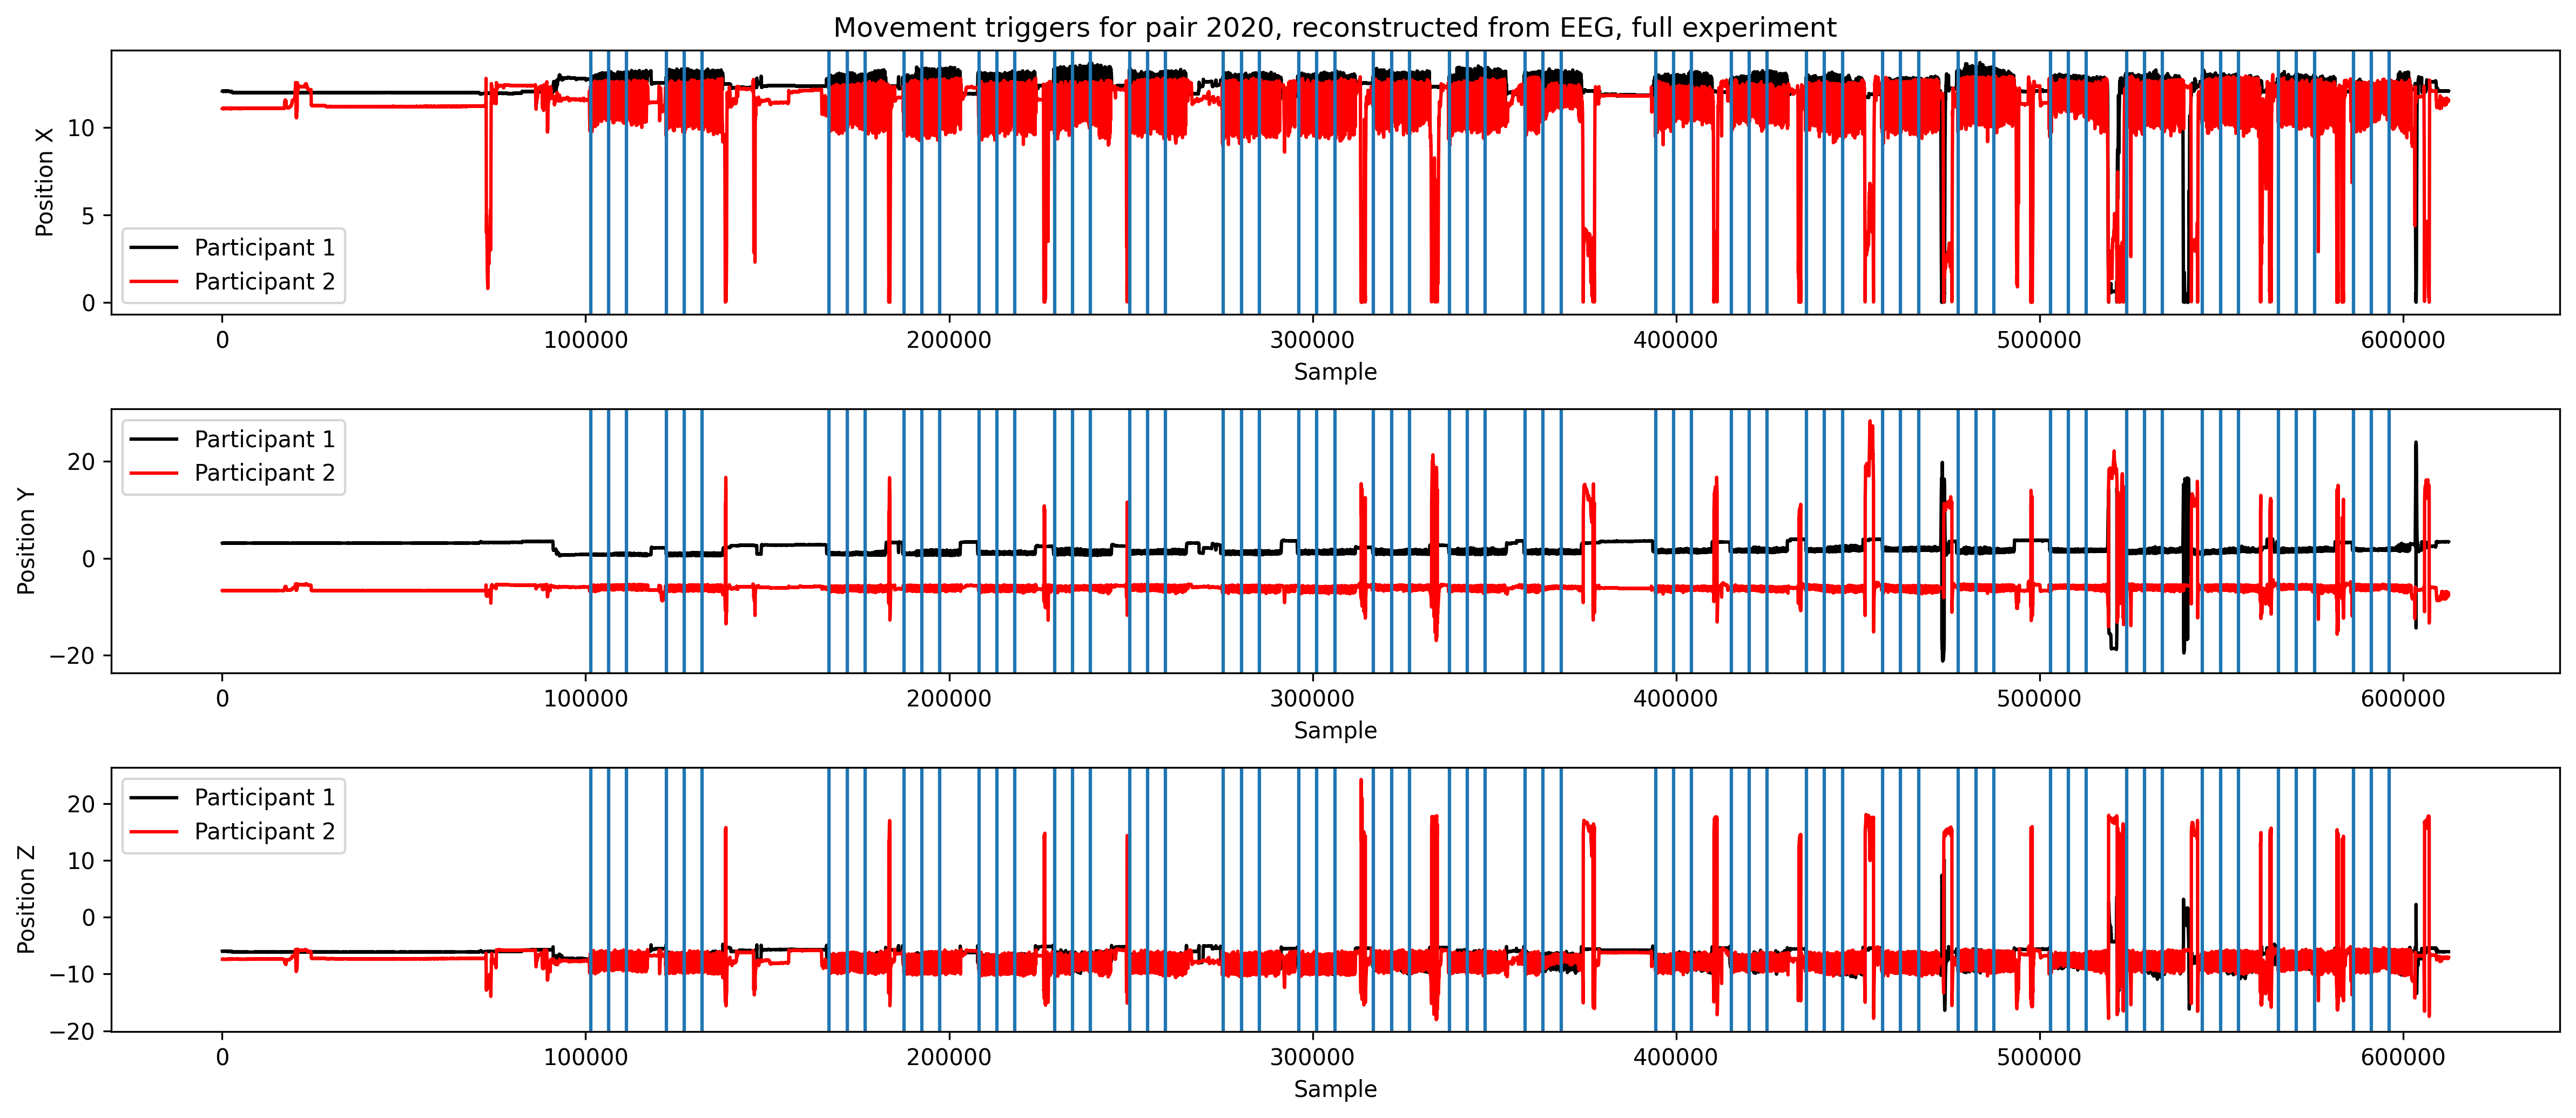

In [7]:
### Reconstructing missing movement triggers for pair 2020 using EEG triggers

### Movement triggers for this pair were reconstructed from EEG triggers.
### The first trigger was manually aligned to the movement onset.
### The alignment of all reconstructed triggers to the movement data was visually verified.

# ~ 1. Loading the data
pair_n = str(2020)
folder_origin = Path(f"data/pair{pair_n}")

polhemus = [i for i in folder_origin.rglob("*polhemus*")][0]
polhemusdata = pd.read_csv(polhemus)
polhemusdata = polhemusdata.rename(columns=
                                   {"Timestamp": "Marker",
                                   "Marker": "Position X", 
                                   "Position X": "Position Y",
                                   "Position Y": "Position Z",
                                   "Position Z": "Timestamp"}).replace({'Timestamp': np.nan}, 0)

# ~ 2. Splitting data for each participant & Interpolating missing samples
p1,p2 = md.split_interpolate(polhemusdata)
# ~ 3. Loading EEG file with triggers
eeg_file = [i for i in folder_origin.rglob("*.bdf")][0]
raw = mne.io.read_raw_bdf(eeg_file, verbose=False)
events = mne.find_events(raw, stim_channel = 'Status',verbose=False)
# ~ 4. Retrieving differences between condition triggers in seconds and transforming them to Polhemus samples
trig_locations = [i[0] for i in events if i[2] in [11,12,13]] # triggers corresponding to conditions
diffs = []
for i in range(1,len(trig_locations)):
    diffs.append(round((trig_locations[i]-trig_locations[i-1])/2048*240)) # 2048 is EEG fs, 240 is Polhemus fs
# ~ 5. Setting triggers from a visually selected starting point, 
# taking into account a delay between the sound, signalling the beggining of movement, and the formal trial start
onsets = [101400]
for i in range(0,len(diffs)):
    onsets.append(onsets[i]+diffs[i])
# ~ 6. Visualizing 1D positions of the pair with condition start markers to check how well is the data aligned
plt.figure(figsize=(16, 7), dpi=300)

plt.subplot(3,1,1)
plt.plot(p1["Sample"],p1["Position X"], label="Participant 1", color = 'black')
plt.plot(p2["Sample"],p2["Position X"], label="Participant 2", color = 'red')
plt.xlabel('Sample')
plt.ylabel('Position X')
for i in range(0,len(onsets)): # plotting triggers
    plt.axvline(x=onsets[i])
plt.legend()
plt.title('Movement triggers for pair 2020, reconstructed from EEG, full experiment')

plt.subplot(3,1,2)
plt.plot(p1["Sample"],p1["Position Y"], label="Participant 1", color = 'black')
plt.plot(p2["Sample"],p2["Position Y"], label="Participant 2", color = 'red')
plt.xlabel('Sample')
plt.ylabel('Position Y')
for i in range(0,len(onsets)): # plotting triggers
    plt.axvline(x=onsets[i])
plt.legend()

plt.subplot(3,1,3)
plt.plot(p1["Sample"],p1["Position Z"], label="Participant 1", color = 'black')
plt.plot(p2["Sample"],p2["Position Z"], label="Participant 2", color = 'red')
plt.xlabel('Sample')
plt.ylabel('Position Z')
for i in range(0,len(onsets)): # plotting triggers
    plt.axvline(x=onsets[i])
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
### Preprocessing all pairs and calculating trial-long movement synchronization

### Steps:
# ~ 1. Split the data file into separate recordings for each participant
# ~ 2. Interpolate missing samples using PCHIP (Piecewise Cubic Hermite Interpolating Polynomial) interpolation
# ~ 3. Divide into 20-sec segments by condition and return only experimental rounds (20 trials)
# ~ 4. Extract only X dimension (vertical, which has the highest signal amplitude)
# ~ 5. Normalize using z-score
# ~ 6. Filter (low-pass 10 Hz, FIR)
# ~ 7. Extract phase using Hilbert transform
# ~ 8. Calculate phase-based synchronization: abs(CCor) and PLV

pairs = [2010,2020,2030,2040,2050,2060,2070,2080,2090,2100,2110,2120,2130,2140,2150,2160,2170,2180,2190,2200,
         2210,2220,2230,2240,2250,2260,2270,2280,2290,2300,2310,2320,2330,2340,2350,2360,2370,2380,2390,
         2410,2420,2430,2440,2450,2460,2470,2480,2490,2500,2510,2520,2530]


ccor_results = [] # collecting all trial-level absolute circular correlation
plv_results = [] # collecting all trial-level PLV
phase_list = [] # collecting continuous phase
acceleration_list = [] # collecting continuous kinematics (vertical axis only)

for pair_n in pairs:
    print(f"Working with pair {pair_n}...")
    folder_origin = Path(f"data/pair{pair_n}")

    if pair_n == 2020: ### to account for missing trial markers in this pair (the trial markers were reconstructed from EEG)
        onsets = [i for i in folder_origin.rglob("onsets*")][0]
        onsets = pd.read_csv(onsets)
        onsets = [int(i) for i in list(onsets.columns)[:-1]]
    polhemus = [i for i in folder_origin.rglob("*polhemus*")][0]
    polhemusdata = pd.read_csv(polhemus)
    polhemusdata = polhemusdata.rename(columns=
                                {"Timestamp": "Marker",
                                "Marker": "Position X", 
                                "Position X": "Position Y",
                                "Position Y": "Position Z",
                                "Position Z": "Timestamp"}).replace({'Timestamp': np.nan}, 0)

    ### 1–2 Splitting data for each participant & interpolating missing samples
    pp1,pp2 = md.split_interpolate(polhemusdata)

    ### 3. Dividing into 20-sec segments by condition and returning only experimental rounds (20 trials)
    if pair_n == 2020:
        def return_by_condition_custom(p1,n_tr,onsets):
            trial_onsets = onsets[-n_tr*3:]
            c1 = [pd.DataFrame(p1).iloc[i:i+20*240,:] for i in trial_onsets[::3]]
            c2 = [pd.DataFrame(p1).iloc[i:i+20*240,:] for i in trial_onsets[1::3]]
            c3 = [pd.DataFrame(p1).iloc[i:i+20*240,:] for i in trial_onsets[2::3]]
            return(c1,c2,c3)
        conds_pp1 = return_by_condition_custom(pp1,20,onsets)
        conds_pp2 = return_by_condition_custom(pp2,20,onsets)
    else:
        if pair_n == 2450: ### to account for one additional trial for this pair, which which was added due to BioSemi crash,
            n_trials = 21  ### this additional trial will be excluded later for movement analysis (step 8 in this cell)
        else:
            n_trials = 20
        conds_pp1 = md.return_by_condition(pp1,n_trials)
        conds_pp2 = md.return_by_condition(pp2,n_trials)

    ### 4. Exracting X dimension
    ### 5. Normalizing using z-score, 
    ### 6. Filtering,   
    ### 7. Extracting phase
    freq_cutoff = 10
    phase = ([md.zscore_filter_phase_1d(i,freq_cutoff) for i in conds_pp1],[md.zscore_filter_phase_1d(k,freq_cutoff) for k in conds_pp2])
    phase_list.append(phase)

    ### 8. Accumulating z-scored and filtered X-dimension movement without phase
    acceleration = ([md.zscore_filter_1d(i,freq_cutoff) for i in conds_pp1],[md.zscore_filter_1d(k,freq_cutoff) for k in conds_pp2])
    acceleration_list.append(acceleration)

    ### 9. Calculating CCOR (uniform) and PLV for each [c]ondition for each [t]rial
    ccor_one_pair = []
    plv_one_pair = []
    pli_one_pair = []
    for c in range(0,3):
        ccor_one_cond = []
        plv_one_cond = []
        pli_one_cond = []
        for t in range(0,20):
            ccor_one_cond.append(abs(md.ccorr_uniform(phase[0][c][t],phase[1][c][t])))
            plv_one_cond.append(md.plv_custom(phase[0][c][t],phase[1][c][t]))
        ccor_one_pair.append(ccor_one_cond)
        plv_one_pair.append(plv_one_cond)
    ccor_results.append(ccor_one_pair)
    plv_results.append(plv_one_pair)

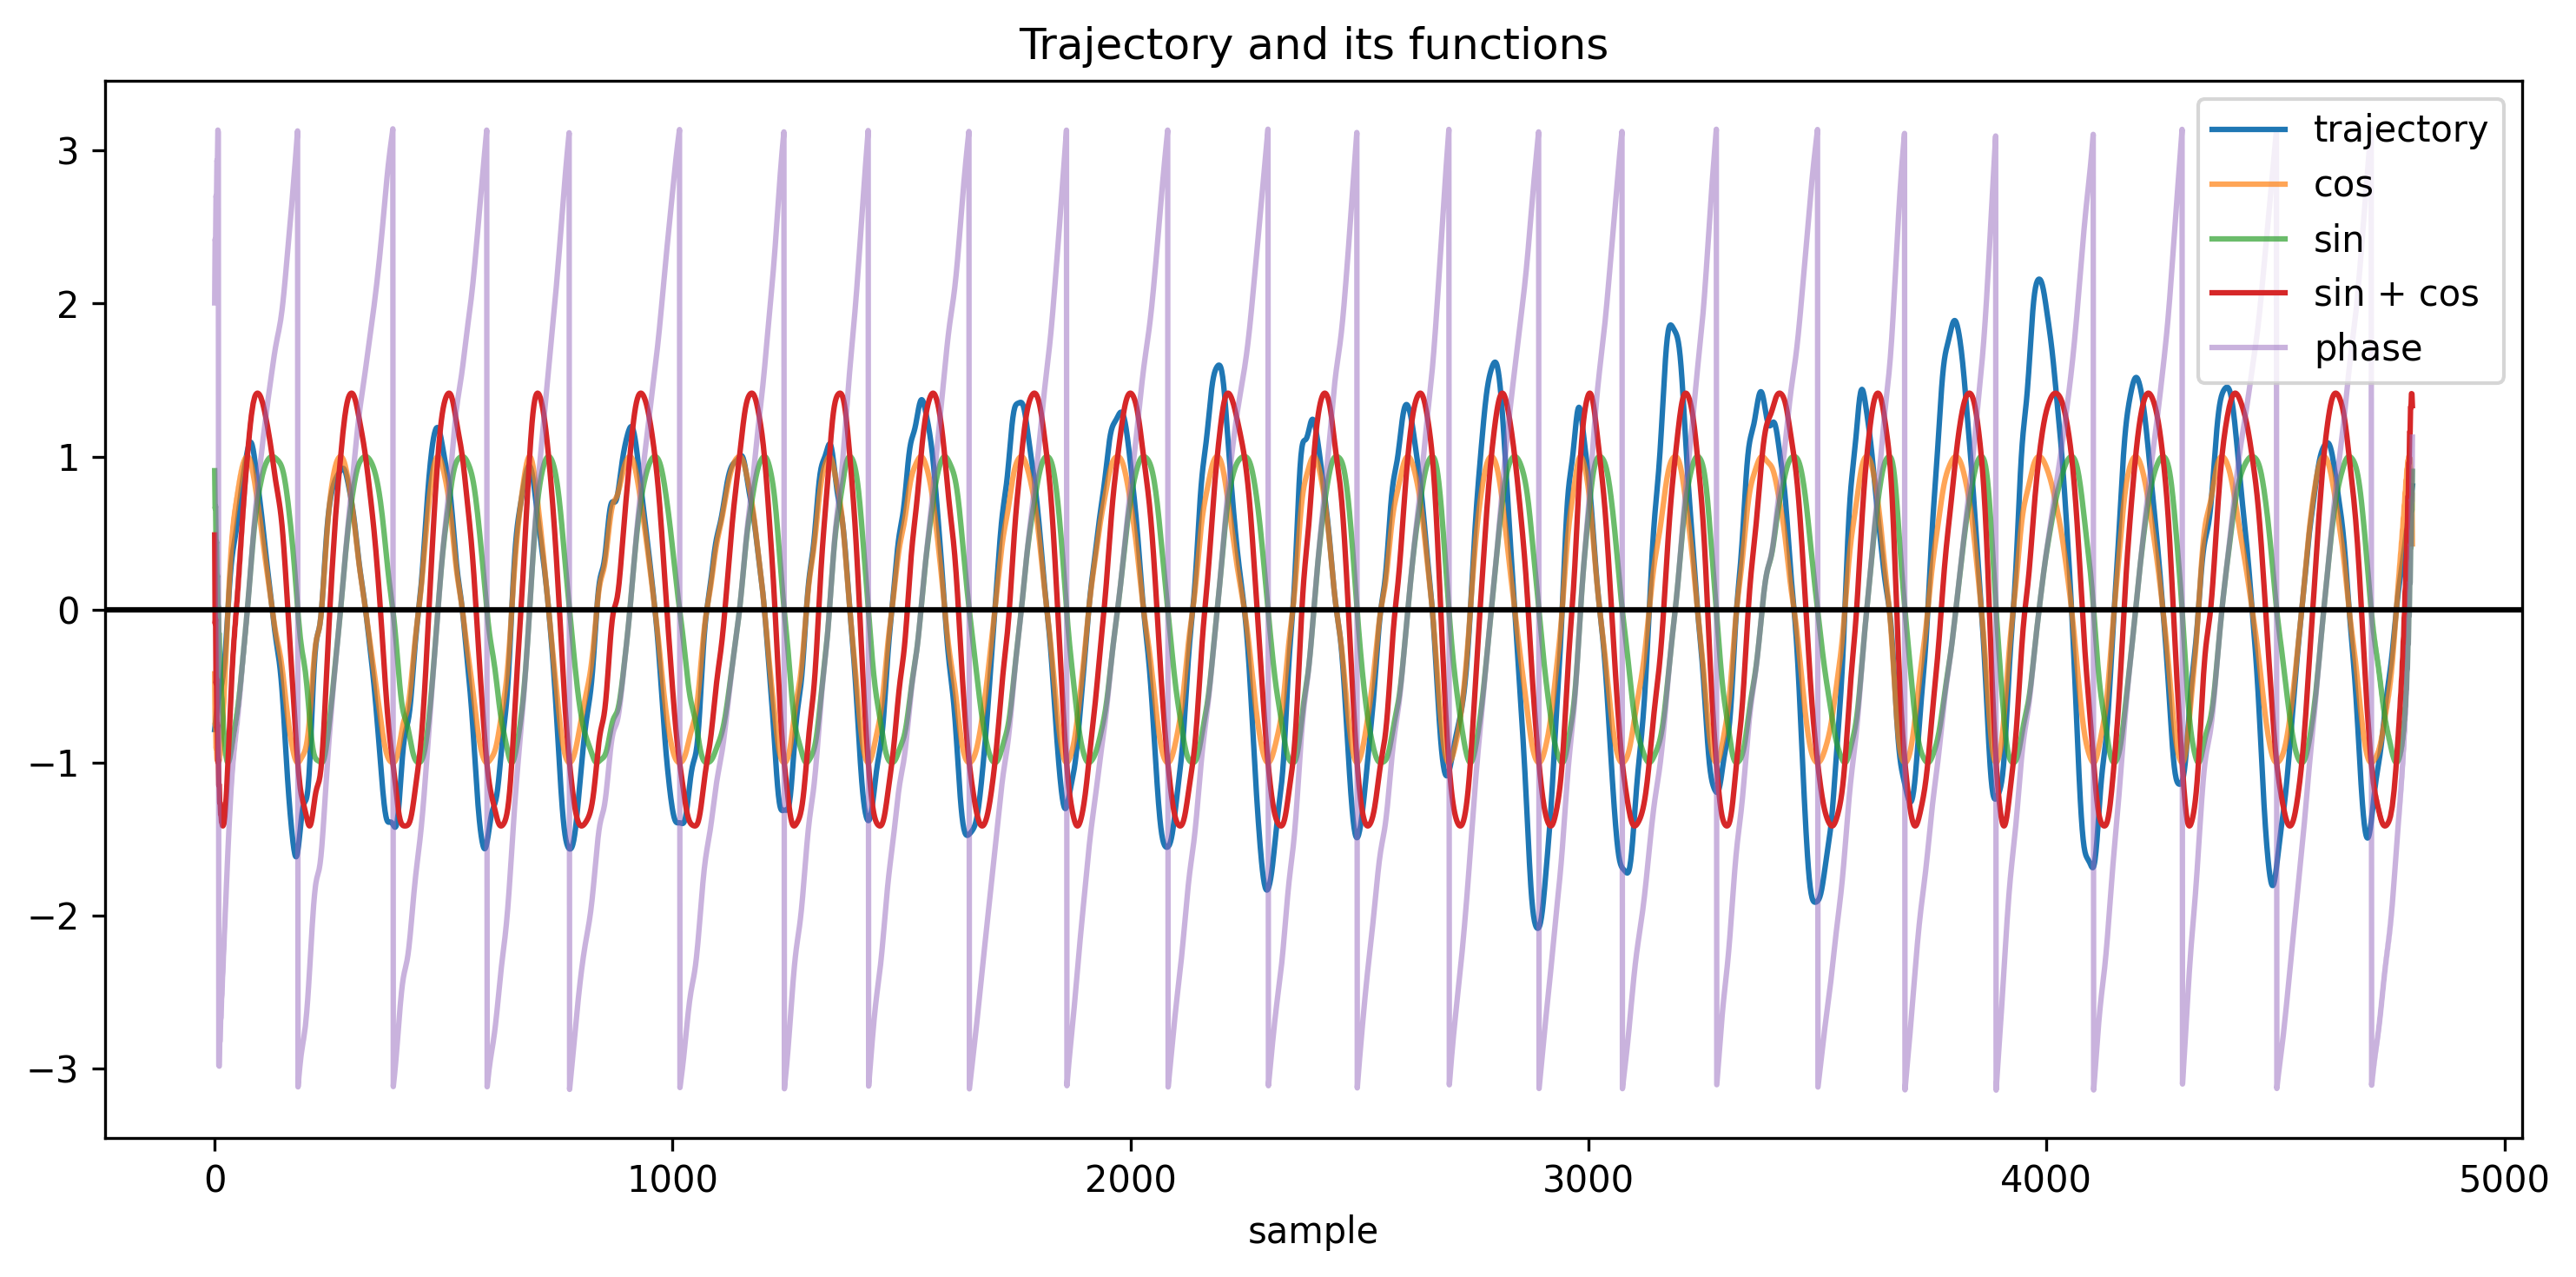

In [74]:
plt.figure(figsize=(10,5),dpi=300)

trial = 10

plt.plot(acceleration_list[0][1][1][trial],label = 'trajectory')
plt.plot(np.cos(phase_list[0][1][1][trial]),alpha=0.7,label='cos')
plt.plot(np.sin(phase_list[0][1][1][trial]),alpha=0.7,label='sin')
plt.plot(np.sin(phase_list[0][1][1][trial]) + np.cos(phase_list[0][1][1][trial]),label='sin + cos')
plt.plot(phase_list[0][1][1][trial],alpha=0.5,label ='phase')
plt.axhline(y=0,color='black')
plt.xlabel('sample')
plt.title('Trajectory and its functions')

plt.legend()
plt.tight_layout()
plt.show()

In [3]:
folder_origin = Path(f"intermediate_files")
os.chdir(folder_origin)

# ~ Save
#with open('phase_list.pickle', 'wb') as handle:
#    pickle.dump(phase_list, handle, protocol=pickle.HIGHEST_PROTOCOL)
#with open('ccor_results.pickle', 'wb') as handle:
#    pickle.dump(ccor_results, handle, protocol=pickle.HIGHEST_PROTOCOL)
#with open('plv_results.pickle', 'wb') as handle:
#    pickle.dump(plv_results, handle, protocol=pickle.HIGHEST_PROTOCOL)


# ~ Open
with open('phase_list.pickle', 'rb') as handle:
    phase_list = pickle.load(handle)
with open('ccor_results.pickle', 'rb') as handle:
    ccor_results = pickle.load(handle)
with open('plv_results.pickle', 'rb') as handle:
    plv_results = pickle.load(handle)

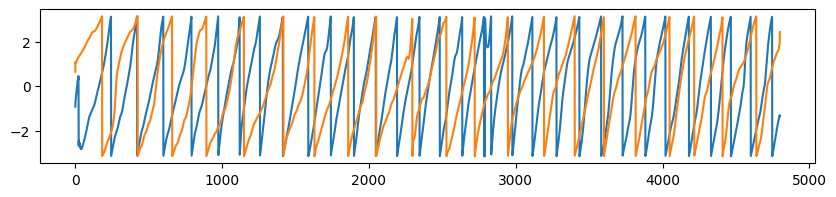

0.07881915630864493
0.10472207670841924


In [8]:
plt.figure(figsize=(10,2))
x = phase_list[0][0][1][11]
y = phase_list[0][1][1][0]
plt.plot(x)
plt.plot(y)
plt.show()
print(md.ccorr_uniform(x,y))
print(md.plv_custom(x,y))

### Phase Locking Value (PLV)

In [4]:
measure = 'Phase Locking Value'
data = md.averages_across_trials(plv_results)
number_trials = len(plv_results)

fontsize = 10


ddf = pd.DataFrame({'Condition': [['Before']*number_trials+['Vision']*number_trials+['After']*number_trials][0],
                    f'{measure}': [data[0]+data[1]+data[2]][0]})

f, ax = plt.subplots(figsize=(12, 6),dpi=1000)

dy = f'{measure}'; dx = "Condition"; ort = "v"
# Draw a violinplot with a narrower bandwidth than the default
ax=pt.half_violinplot(data = ddf, palette = "Set2", bw=.2,  linewidth=1,cut=0.,\
                   scale="area", width=.8, inner=None,orient=ort,x=dx,y=dy)
ax=sns.stripplot(data=ddf, palette="Set2", edgecolor="white",size=5,orient=ort,\
                 x=dx,y=dy,jitter=0.05,zorder=0)
ax=sns.boxplot(data=ddf, color="black",orient=ort,width=.15,x=dx,y=dy,zorder=10,\
              showcaps=True,boxprops={'facecolor':'none', "zorder":10},\
               showfliers=True,whiskerprops={'linewidth':2, "zorder":10},saturation=1,fliersize=0)
for i in range(0,52):
    ax.plot([0,1],[data[0][i],data[1][i]],'--',alpha=0.1,linewidth=1,color='gray')
    ax.plot([1,2],[data[1][i],data[2][i]],'--',alpha=0.1,linewidth=1,color='gray')
ax.plot([0,1],[0.84,0.84],color='black')
ax.text(x=0.42,y=0.84,s='***')
ax.plot([1,2],[0.89,0.89],color='black')
ax.text(x=1.42,y=0.89,s='***')
ax.plot([0,2],[0.95,0.95],color='black')
ax.text(x=0.94,y=0.95,s='*')
ax.set(ylim=(0, 1))
ax.grid(visible=True)
ax.set_xticklabels(['Before','Vision','After'],fontfamily="Arial",fontsize=fontsize)
ax.set_xlabel('Condition',fontfamily="Arial",fontsize=fontsize)
ax.set_ylabel('Movement synchronization (PLV)',fontfamily="Arial",fontsize=fontsize)
#ax.set_title('',fontfamily="Arial")
sns.despine(left=True)

In [5]:
### Get medians and the interquartile range
def iqr_fun(data):
    Q1 = np.percentile(data, 25)
    Q3 = np.percentile(data, 75)
    return Q3 - Q1

print(f'Before. Median = {round(np.median(data[0]),3)}. IQR = {round(iqr_fun(data[0]),3)}')
print(f'Vision. Median = {round(np.median(data[1]),3)}. IQR = {round(iqr_fun(data[1]),3)}')
print(f'After. Median = {round(np.median(data[2]),3)}. IQR = {round(iqr_fun(data[2]),3)}')

Before. Median = 0.098. IQR = 0.063
Vision. Median = 0.152. IQR = 0.183
After. Median = 0.11. IQR = 0.069


In [6]:
### Get the p-values
print(f"Closed1 vs Open: p-val = {scipy.stats.wilcoxon(data[0],data[1])[1]*3}")
print(f"Closed2 vs Open: p-val = {scipy.stats.wilcoxon(data[2],data[1])[1]*3}")
print(f"Closed1 vs Closed2: p-val = {scipy.stats.wilcoxon(data[0],data[2])[1]*3}")

Closed1 vs Open: p-val = 3.3885528603436864e-08
Closed2 vs Open: p-val = 1.881384582435286e-05
Closed1 vs Closed2: p-val = 0.010697583598923512


In [6]:
### Investigating the effect of outliers

# Restricting to zscore <= 1 in the Vision condition
indices_to_keep = [i for i in range(0,len(data[1])) if scipy.stats.zscore(data[1])[i] <= 1]

measure = 'Phase Locking Value'
new_data = (np.array(data[0])[indices_to_keep],np.array(data[1])[indices_to_keep],np.array(data[2])[indices_to_keep])
new_data = [list(i) for i in new_data]
number_pairs = len(indices_to_keep)

residual_data = ([x for i, x in enumerate(data[0]) if i not in indices_to_keep],
                 [x for i, x in enumerate(data[1]) if i not in indices_to_keep],
                 [x for i, x in enumerate(data[2]) if i not in indices_to_keep])
residual_pairs = len(residual_data[0])

fontsize = 10


new_ddf = pd.DataFrame({'Condition': [['Before']*number_pairs+['Vision']*number_pairs+['After']*number_pairs][0],
                    f'{measure}': [new_data[0]+new_data[1]+new_data[2]][0]})
residual_ddf = pd.DataFrame({'Condition': [['Before']*residual_pairs+['Vision']*residual_pairs+['After']*residual_pairs][0],
                    f'{measure}': [residual_data[0]+residual_data[1]+residual_data[2]][0]})

f, ax = plt.subplots(figsize=(12, 6),dpi=1000)

dy = f'{measure}'; dx = "Condition"; ort = "v"
# Draw a violinplot with a narrower bandwidth than the default
ax=pt.half_violinplot(data = new_ddf, palette = "Set2", bw=.2,  linewidth=1,cut=0.,\
                   scale="area", width=.8, inner=None,orient=ort,x=dx,y=dy)
ax=sns.stripplot(data=new_ddf, palette="Set2", edgecolor="white",size=5,orient=ort,\
                 x=dx,y=dy,jitter=0.05,zorder=0)
ax=sns.boxplot(data=new_ddf, color="black",orient=ort,width=.15,x=dx,y=dy,zorder=10,\
              showcaps=True,boxprops={'facecolor':'none', "zorder":10},\
               showfliers=True,whiskerprops={'linewidth':2, "zorder":10},saturation=1,fliersize=0)
ax=sns.stripplot(data=residual_ddf, color="dimgray", edgecolor="white",size=5,orient=ort,\
                 x=dx,y=dy,jitter=0.05,zorder=0)
for i in range(0,number_pairs):
    ax.plot([0,1],[new_data[0][i],new_data[1][i]],'--',alpha=0.1,linewidth=1,color='gray')
    ax.plot([1,2],[new_data[1][i],new_data[2][i]],'--',alpha=0.1,linewidth=1,color='gray')
ax.plot([0,1],[0.84,0.84],color='black')
ax.text(x=0.42,y=0.84,s='***')
ax.plot([1,2],[0.89,0.89],color='black')
ax.text(x=1.42,y=0.89,s='***')
ax.plot([0,2],[0.95,0.95],color='black')
ax.text(x=0.94,y=0.95,s='*')
ax.set(ylim=(0, 1))
ax.grid(visible=True)
ax.set_xticklabels(['Before','Vision','After'],fontfamily="Arial",fontsize=fontsize)
ax.set_xlabel('Condition',fontfamily="Arial",fontsize=fontsize)
ax.set_ylabel('Movement synchronization (PLV)',fontfamily="Arial",fontsize=fontsize)
#ax.set_title('',fontfamily="Arial")
set2 = plt.get_cmap("Set2").colors

outside = plt.scatter([], [], s=15, color="dimgray")
inside = tuple(plt.scatter([], [], s=15, color=c) for c in set2[:3])  # three dots
from matplotlib.legend_handler import HandlerTuple
plt.legend(
    [outside, inside],
    ["pairs removed by truncation", "retained pairs"],
    handler_map={tuple: HandlerTuple(ndivide=None, pad=1.0)},
    handlelength=3,        # widen the handle box so the dots fit
    frameon=True,
    framealpha=1,
    edgecolor="black",
    loc="upper left",
    borderpad=0.6,
    labelspacing=1.0,
    handletextpad=1,
    fontsize=12,
    bbox_to_anchor=(0.65, 0.7),
)
sns.despine(left=True)

In [7]:
### Get the p-values
print(f"Closed1 vs Open: p-val = {scipy.stats.wilcoxon(new_data[0],new_data[1])[1]*3}")
print(f"Closed2 vs Open: p-val = {scipy.stats.wilcoxon(new_data[2],new_data[1])[1]*3}")
print(f"Closed1 vs Closed2: p-val = {scipy.stats.wilcoxon(new_data[0],new_data[2])[1]*3}")

Closed1 vs Open: p-val = 2.1599703359242994e-08
Closed2 vs Open: p-val = 0.00041838973936592083
Closed1 vs Closed2: p-val = 0.03147181274295008


In [8]:
### Investigating if the Vision condition has higher PLV values than expected by chance

### First, we need to remove one last (additional) trial for pair 43,
### which was added due to EEG system malfunction and was needed to keep the amount of EEG data the same across dyads
phase_list[43][0][0] = phase_list[43][0][0][0:20]
phase_list[43][0][1] = phase_list[43][0][1][0:20]
phase_list[43][0][2] = phase_list[43][0][2][0:20]

phase_list[43][1][0] = phase_list[43][1][0][0:20]
phase_list[43][1][1] = phase_list[43][1][1][0:20]
phase_list[43][1][2] = phase_list[43][1][2][0:20]

phase_ar = np.asarray(phase_list)
phase_ar = phase_ar[:,:,1,:] # keeping only Vision condition
print(phase_ar.shape)

(52, 2, 20, 4800)


In [46]:
# calculate the median of the observed distribution of PLV in the Vision condition
n_pairs = len(phase_ar)

observed_plv = []
for i in range(n_pairs):
    phase = phase_ar[i]
    plv_one_pair = []
    for t in range(0,20):
        plv_one_pair.append(md.plv_custom(phase[0][t],phase[1][t]))
    observed_plv.append(np.median(plv_one_pair))
observed_plv = np.median(observed_plv)
print('Observed median = ', observed_plv)

# calculate the permutation distribution
rng = 123
rng = np.random.default_rng(rng)
n_perm = 1000
all_permutation_plv = []
for perm in range(n_perm):
    new_partners = rng.permutation(n_pairs)
    one_perm_plv = []
    for i in range(n_pairs):
        permuted_pair = new_partners[i]
        phase_subject_a_original = phase_ar[i][0]
        phase_subject_b_permuted = phase_ar[permuted_pair][1]
        plv_one_pair = []
        for t in range(0,20):
            plv_one_pair.append(md.plv_custom(phase_subject_a_original[t],phase_subject_b_permuted[t]))
        one_perm_plv.append(np.median(plv_one_pair)) # median across trials for a pair
    all_permutation_plv.append(np.median(one_perm_plv)) # median across all pairs in a permutation round
print('Permutation median = ', np.median(all_permutation_plv))

p_greater = (np.sum(all_permutation_plv >= observed_plv, axis=0) + 1) / (len(all_permutation_plv) + 1)
p_less    = (np.sum(all_permutation_plv <= observed_plv, axis=0) + 1) / (len(all_permutation_plv) + 1)
p_two_sided = np.minimum(1, 2 * np.minimum(p_greater, p_less))
print(f"p-value = {p_two_sided}")

plt.figure(figsize=(12, 6),dpi=1000)
plt.hist(all_permutation_plv,color='grey',label='permutation distribution')
plt.axvline(x=observed_plv, color = 'red',label='observed median PLV')
plt.xlabel('median PLV across all pairs in a permutation iteration')
plt.ylabel('count')
plt.show()

Observed median =  0.15241499391158142
Permutation median =  0.06413134378562019
p-value = 0.001998001998001998


### Circular Correlation Coefficient

In [17]:
measure = 'Circular correlation (absolute)'
data = md.averages_across_trials(ccor_results)
number_trials = len(ccor_results)

fontsize = 10


ddf = pd.DataFrame({'Condition': [['Before']*number_trials+['Vision']*number_trials+['After']*number_trials][0],
                    f'{measure}': [data[0]+data[1]+data[2]][0]})

f, ax = plt.subplots(figsize=(12, 6),dpi=1000)

dy = f'{measure}'; dx = "Condition"; ort = "v"
# Draw a violinplot with a narrower bandwidth than the default
ax=pt.half_violinplot(data = ddf, palette = "Set2", bw=.2,  linewidth=1,cut=0.,\
                   scale="area", width=.8, inner=None,orient=ort,x=dx,y=dy)
ax=sns.stripplot(data=ddf, palette="Set2", edgecolor="white",size=5,orient=ort,\
                 x=dx,y=dy,jitter=0.05,zorder=0)
ax=sns.boxplot(data=ddf, color="black",orient=ort,width=.15,x=dx,y=dy,zorder=10,\
              showcaps=True,boxprops={'facecolor':'none', "zorder":10},\
               showfliers=True,whiskerprops={'linewidth':2, "zorder":10},saturation=1,fliersize=0)
for i in range(0,52):
    ax.plot([0,1],[data[0][i],data[1][i]],'--',alpha=0.1,linewidth=1,color='gray')
    ax.plot([1,2],[data[1][i],data[2][i]],'--',alpha=0.1,linewidth=1,color='gray')
ax.plot([0,1],[0.84,0.84],color='black')
ax.text(x=0.42,y=0.84,s='***')
ax.plot([1,2],[0.89,0.89],color='black')
ax.text(x=1.42,y=0.89,s='***')
ax.plot([0,2],[0.95,0.95],color='black')
ax.text(x=0.94,y=0.95,s='*')
ax.set(ylim=(0, 1))
ax.grid(visible=True)
ax.set_xticklabels(['Before','Vision','After'],fontfamily="Arial",fontsize=fontsize)
ax.set_xlabel('Condition',fontfamily="Arial",fontsize=fontsize)
ax.set_ylabel('Circular correlation (absolute)',fontfamily="Arial",fontsize=fontsize)
#ax.set_title('Movement synchronization: Circular correlation',fontfamily="Arial")
sns.despine(left=True)

In [11]:
print(f"Closed1 vs Open: p-val = {scipy.stats.wilcoxon(data[0],data[1])[1]*3}")
print(f"Closed2 vs Open: p-val = {scipy.stats.wilcoxon(data[2],data[1])[1]*3}")
print(f"Closed1 vs Closed2: p-val = {scipy.stats.wilcoxon(data[0],data[2])[1]*3}")

Closed1 vs Open: p-val = 2.590477035532419e-08
Closed2 vs Open: p-val = 4.165133215253526e-06
Closed1 vs Closed2: p-val = 0.01201431343512666


In [13]:
print(f'Before. Median = {round(np.median(data[0]),3)}')
print(f'Vision. Median = {round(np.median(data[1]),3)}')
print(f'After. Median = {round(np.median(data[2]),3)}')

Before. Median = 0.081
Vision. Median = 0.143
After. Median = 0.088
